In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [17]:
import joblib

rf_model = joblib.load("../models/random_forest_model.pkl")

In [2]:
X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

In [4]:
preds = pd.read_csv("../data/processed/model_predictions.csv")

y_test = preds["y_test"]
y_pred_lr = preds["y_pred_lr"]
y_pred_dt = preds["y_pred_dt"]
y_pred_rf = preds["y_pred_rf"]

Logistic Regression confusion matrix

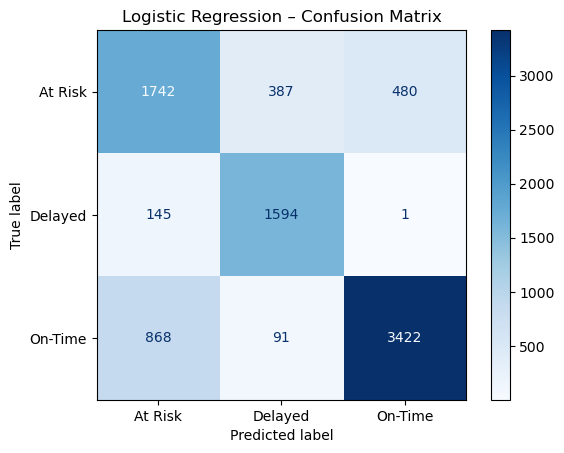

In [5]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["At Risk", "Delayed", "On-Time"]
)

disp_lr.plot(cmap="Blues")
plt.title("Logistic Regression – Confusion Matrix")
plt.show()

Decision Tree confusion matrix

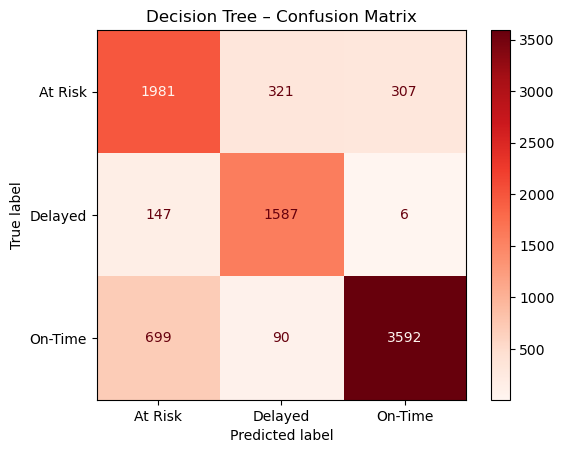

In [9]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["At Risk", "Delayed", "On-Time"]
)

disp_dt.plot(cmap="Reds")
plt.title("Decision Tree – Confusion Matrix")
plt.show()

Random Forest confusion matrix

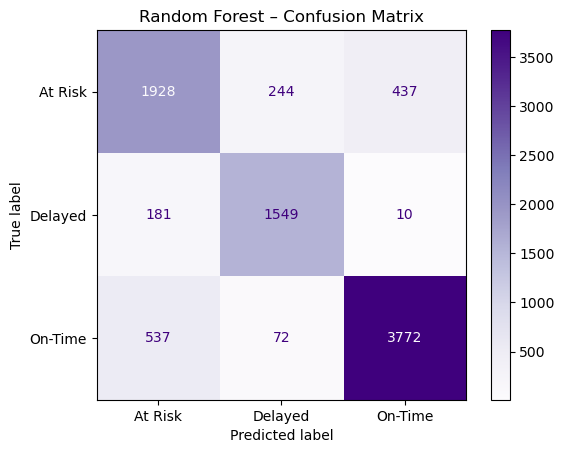

In [10]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["At Risk", "Delayed", "On-Time"]
)

disp_rf.plot(cmap="Purples")
plt.title("Random Forest – Confusion Matrix")
plt.show()

#### Class-wise metric comparison

In [11]:
from sklearn.metrics import classification_report

lr_report = classification_report(y_test, y_pred_lr, output_dict=True)
dt_report = classification_report(y_test, y_pred_dt, output_dict=True)
rf_report = classification_report(y_test, y_pred_rf, output_dict=True)

Build Comparision Table

In [12]:
comparison_df = pd.DataFrame({
    "Logistic Regression": {
        "Delayed_Precision": lr_report["1"]["precision"],
        "Delayed_Recall": lr_report["1"]["recall"],
        "Delayed_F1": lr_report["1"]["f1-score"],
        "Macro_F1": lr_report["macro avg"]["f1-score"]
    },
    "Decision Tree": {
        "Delayed_Precision": dt_report["1"]["precision"],
        "Delayed_Recall": dt_report["1"]["recall"],
        "Delayed_F1": dt_report["1"]["f1-score"],
        "Macro_F1": dt_report["macro avg"]["f1-score"]
    },
    "Random Forest": {
        "Delayed_Precision": rf_report["1"]["precision"],
        "Delayed_Recall": rf_report["1"]["recall"],
        "Delayed_F1": rf_report["1"]["f1-score"],
        "Macro_F1": rf_report["macro avg"]["f1-score"]
    }
})

comparison_df

,Logistic Regression,Decision Tree,Random Forest
Delayed_Precision,0.769305,0.794294,0.830563
Delayed_Recall,0.916092,0.912069,0.890230
Delayed_F1,0.836306,0.849117,0.859362
Macro_F1,0.770664,0.814989,0.823450


#### Error Analysis
what Random Forest gets wrong.

In [14]:
errors_rf = X_test.copy()
errors_rf["True_Label"] = y_test
errors_rf["Predicted_Label"] = y_pred_rf

misclassified = errors_rf[
    errors_rf["True_Label"] != errors_rf["Predicted_Label"]
]
misclassified.shape

(1481, 66)

Delayed predicted as On-Time.

In [15]:
dangerous_errors = misclassified[
    (misclassified["True_Label"] == 1) &
    (misclassified["Predicted_Label"] == 2)
]

dangerous_errors.head()

,Agent_Age,Agent_Rating,Pickup_Next_Day,Distance,Extreme_Distance_Flag,Night_Order_Flag,Order_Hour,Weekend_Flag,Peak_Hour_Flag,Weather_Fog,...,Distance_Vehicle_20–50_scooter,Distance_Vehicle_20–50_van,Distance_Vehicle_300+_motorcycle,Distance_Vehicle_300+_scooter,Distance_Vehicle_300+_van,Distance_Vehicle_5–10_motorcycle,Distance_Vehicle_5–10_scooter,Distance_Vehicle_5–10_van,True_Label,Predicted_Label
30,-0.787849,0.205334,0,-0.074474,0,0,0.532842,0,1,False,...,False,False,False,False,False,False,False,False,1,2
1490,0.601200,0.845099,0,-0.079832,0,0,-1.331153,0,1,False,...,False,False,False,False,False,False,False,False,1,2
1895,1.642987,-2.033845,0,-0.069411,0,0,-1.124042,0,0,False,...,False,False,False,False,False,True,False,False,1,2
3143,-1.308742,0.525217,0,-0.079827,0,0,-1.952484,0,1,False,...,False,False,False,False,False,False,False,False,1,2
5647,0.427569,-1.394079,0,-0.079574,0,0,-1.952484,0,1,False,...,False,False,False,False,False,False,False,False,1,2


#### Feature Importance (Random Forest)
Extract importance

In [18]:
importances = pd.Series(
    rf_model.feature_importances_,
    index=X_test.columns
).sort_values(ascending=False)
importances.head(10)

Distance                             0.295182
Order_Hour                           0.117713
Agent_Age                            0.109579
Agent_Rating                         0.089768
Distance_Bucket_10–20                0.052127
Distance_Bucket_5–10                 0.033038
Night_Order_Flag                     0.020909
Distance_Vehicle_10–20_motorcycle    0.018031
Traffic_Low                          0.016378
Weekend_Flag                         0.015326
dtype: float64

Top features

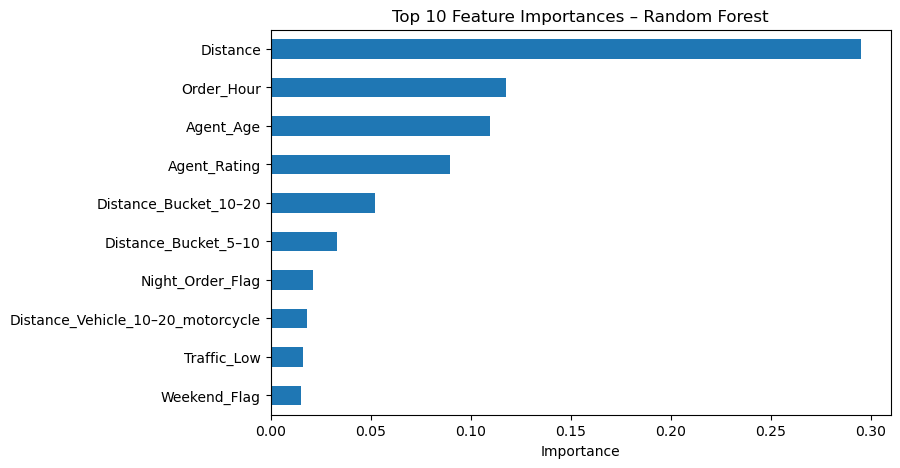

In [19]:
plt.figure(figsize=(8, 5))
importances.head(10).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 Feature Importances – Random Forest")
plt.xlabel("Importance")
plt.show()